# Detecção de fraudes em transações

Projeto de classificação binária para identificar transações fraudulentas. A base contém variáveis `V1` a `V28` transformadas por PCA, além de `Time`, `Amount` e `Class`.

> A fraude representa cerca de 0,17% dos registros. Por isso, acurácia isolada não descreve a utilidade do modelo: acompanharemos precisão, recall e F1 da classe 1.

In [1]:
import pandas as pd
url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

df = pd.read_csv(url)

df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Problema de classificação desbalanceada

A classe positiva é muito rara. Um classificador que sempre prevê transação normal teria cerca de 99,8% de acurácia, mas recall zero para fraude. Neste trabalho, o recall da classe `1` é a métrica prioritária, sempre acompanhado da precisão para expor o custo de falsos alertas.

In [2]:
df["Class"].value_counts(normalize=True)

Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64

## Feature Engineering

Criamos variaveis que ajudam o modelo.

Significa criar ou transformar variaveis para nosso modelo melhorar

ex.: padrões de comportamento ao longo de tempo, variaveis com valor normalizado da transação

In [3]:
import numpy as np

df["Amount_log"] = np.log1p(df["Amount"])
df[["Amount", "Amount_log"]].head()

,Amount,Amount_log
0,149.62,5.014760
1,2.69,1.305626
2,378.66,5.939276
3,123.50,4.824306
4,69.99,4.262539


A transformação logarítmica reduz a assimetria de `Amount`. O escalonamento será ajustado somente com os dados de treino, depois da divisão, para evitar vazamento de informação do conjunto de teste.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Primeiro separamos o teste final. Ele fica intocado até a avaliacao final.
X = df.drop("Class", axis=1)
y = df["Class"]
X_dev, X_test_raw, y_dev, y_test = train_test_split(
    X, y, stratify=y, test_size=0.30, random_state=42
)
# A validacao serve para escolher o limiar. O modelo baseline aprende somente em X_fit.
X_fit, X_val_raw, y_train, y_val = train_test_split(
    X_dev, y_dev, stratify=y_dev, test_size=0.20, random_state=42
)

scaler = StandardScaler()
x_train = pd.DataFrame(scaler.fit_transform(X_fit), columns=X.columns, index=X_fit.index)
x_val = pd.DataFrame(scaler.transform(X_val_raw), columns=X.columns, index=X_val_raw.index)
x_test = pd.DataFrame(scaler.transform(X_test_raw), columns=X.columns, index=X_test_raw.index)
print("Fraudes no treino:", y_train.mean())
print("Fraudes na validacao:", y_val.mean())
print("Fraudes no teste:", y_test.mean())

Fraudes no treino: 0.0017242352233041362
Fraudes na validacao: 0.0017304943194642992
Fraudes no teste: 0.0017321489179921118


## Logistic Regression

In [5]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=2000)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)
model_val_probs = model.predict_proba(x_val)[:, 1]

In [6]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.86      0.63      0.73       148

    accuracy                           1.00     85443
   macro avg       0.93      0.81      0.86     85443
weighted avg       1.00      1.00      1.00     85443



A acuracia arredondada para 1,00 esconde erros na classe minoritaria. Na linha `1`, precisao indica quantos alertas eram fraude, recall indica quantas fraudes foram encontradas e F1 resume o equilibrio entre os dois. Use o relatorio para comparar os modelos: maior recall reduz fraudes perdidas, enquanto menor precisao gera mais alertas falsos.

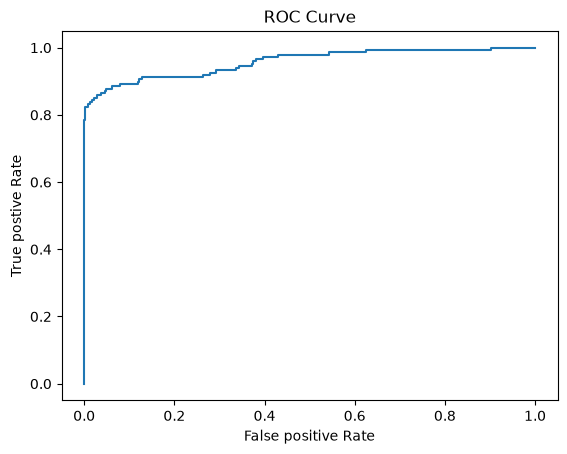

AUC: 0.9574274814118886


In [7]:
#Curva Roc
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_probs = model.predict_proba(x_test)[:,1]
fpr, tpr, _ = roc_curve(y_test, y_probs)

plt.plot(fpr, tpr)
plt.title("ROC Curve")
plt.xlabel("False positive Rate")
plt.ylabel("True postive Rate")
plt.show()

print("AUC:", roc_auc_score(y_test,y_probs))

 A curva ROC mostra a relação entre taxa de verdadeiros positivos e falsos positivos em vários limiares. Com classes muito desbalanceadas, avalie também a curva precisão-recall, mais informativa sobre a classe rara.

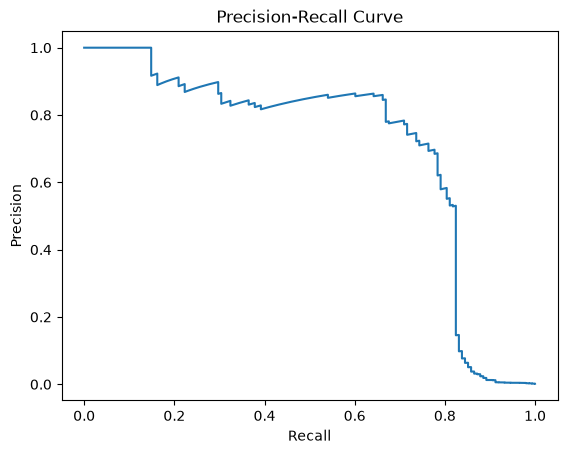

In [8]:
from sklearn.metrics import precision_recall_curve
precision, recall, _ = precision_recall_curve(y_test, y_probs)

plt.plot(recall, precision)
plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()

## Balanceamento de dados

In [9]:
# Undersampling aplicado somente ao conjunto de treino.
train_data = x_train.copy()
train_data["Class"] = y_train
fraudes = train_data[train_data["Class"] == 1]
normais = train_data[train_data["Class"] == 0].sample(len(fraudes), random_state=42)
train_under = pd.concat([fraudes, normais]).sample(frac=1, random_state=42)
x_under = train_under.drop(columns="Class")
y_under = train_under["Class"]
print(y_under.value_counts())

Class
1    275
0    275
Name: count, dtype: int64


In [10]:
# Oversampling com SMOTE aplicado somente ao conjunto de treino.
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
x_res, y_res = smote.fit_resample(x_train, y_train)
print(y_res.value_counts())

Class
0    159216
1    159216
Name: count, dtype: int64


### Comparacao do balanceamento

Para isolar o efeito da amostragem, comparamos a mesma regressao logistica em tres versoes do treino: original, undersampling e SMOTE. Todas sao avaliadas no mesmo conjunto de teste original, com limiar 0,50. O teste nao participa da amostragem nem do ajuste.

In [11]:
from sklearn.metrics import precision_recall_fscore_support

sampling_experiments = {
    "Treino original": (x_train, y_train),
    "Undersampling": (x_under, y_under),
    "SMOTE": (x_res, y_res),
}
sampling_rows = []
sampling_models = {}
for name, (X_sample, y_sample) in sampling_experiments.items():
    sample_model = LogisticRegression(max_iter=2000, random_state=42)
    sample_model.fit(X_sample, y_sample)
    sample_pred = sample_model.predict(x_test)
    p, r, f, _ = precision_recall_fscore_support(
        y_test, sample_pred, labels=[1], average=None, zero_division=0
    )
    sampling_rows.append({"Metodo": name, "Precisao fraude": p[0], "Recall fraude": r[0], "F1 fraude": f[0]})
    sampling_models[name] = sample_model
sampling_comparison = pd.DataFrame(sampling_rows).set_index("Metodo")
sampling_comparison.round(3)

,Precisao fraude,Recall fraude,F1 fraude
Metodo,,,
Treino original,0.861,0.628,0.727
Undersampling,0.045,0.885,0.085
SMOTE,0.060,0.872,0.112


In [12]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)

rf.fit(x_train,y_train)

y_pred_rf = rf.predict(x_test)

print(classification_report(y_test,y_pred_rf))
#recall deu uma boa melhorada!!!

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.78      0.79      0.79       148

    accuracy                           1.00     85443
   macro avg       0.89      0.90      0.89     85443
weighted avg       1.00      1.00      1.00     85443



In [13]:
# Exemplo de pipeline balanceado: fit somente no conjunto de desenvolvimento, teste final preservado.
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))
])
pipeline.fit(X_dev, y_dev)
y_pred_pipeline = pipeline.predict(X_test_raw)
print(classification_report(y_test, y_pred_pipeline, digits=3))

              precision    recall  f1-score   support

           0      1.000     0.978     0.989     85295
           1      0.065     0.878     0.122       148

    accuracy                          0.978     85443
   macro avg      0.533     0.928     0.555     85443
weighted avg      0.998     0.978     0.987     85443



In [14]:
from sklearn.metrics import classification_report, precision_recall_curve

# Escolhemos no conjunto de validacao o limiar com maior precisao que alcance recall minimo de 0,80.
# O conjunto de teste so e usado depois dessa decisao.
target_recall = 0.80
val_precision, val_recall, val_thresholds = precision_recall_curve(y_val, model_val_probs)
valid = val_recall[:-1] >= target_recall
if valid.any():
    best_idx = int(val_precision[:-1][valid].argmax())
    threshold = float(val_thresholds[valid][best_idx])
else:
    best_idx = int(val_recall[:-1].argmax())
    threshold = float(val_thresholds[best_idx])
    print("Aviso: a validacao nao atingiu recall 0,80; usado o limiar de maior recall.")

y_pred_custom = (model.predict_proba(x_test)[:, 1] >= threshold).astype(int)
print(f"Limiar escolhido na validacao: {threshold:.4f}")
print(f"Recall minimo desejado: {target_recall:.2f}")
print("Desempenho no teste final:")
print(classification_report(y_test, y_pred_custom, digits=3))

Limiar escolhido na validacao: 0.1147
Recall minimo desejado: 0.80
Desempenho no teste final:
              precision    recall  f1-score   support

           0      1.000     1.000     1.000     85295
           1      0.746     0.716     0.731       148

    accuracy                          0.999     85443
   macro avg      0.873     0.858     0.865     85443
weighted avg      0.999     0.999     0.999     85443



## Modelo avançado: XGBoost

O `scale_pos_weight` aumenta o custo relativo de errar a classe minoritária. O valor deve ser escolhido por validação; a proporção entre classes no treino é um ponto de partida.

In [15]:
from xgboost import XGBClassifier

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
xgb = XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)
xgb.fit(x_train, y_train)
y_pred_xgb = xgb.predict(x_test)

In [16]:
print(classification_report(y_test, y_pred_xgb))
#grande melhora de recall, f1-score com bom equilibrio de precisao de recall

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.89      0.78      0.83       148

    accuracy                           1.00     85443
   macro avg       0.95      0.89      0.92     85443
weighted avg       1.00      1.00      1.00     85443



In [17]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_xgb, digits=3))

              precision    recall  f1-score   support

           0      1.000     1.000     1.000     85295
           1      0.891     0.777     0.830       148

    accuracy                          0.999     85443
   macro avg      0.946     0.888     0.915     85443
weighted avg      0.999     0.999     0.999     85443



O grafico mostra a importancia por ganho do XGBoost, nao a direcao causal da relacao. Como `V1` a `V28` sao componentes PCA, nao possuem interpretacao direta como atributos originais do cartao. A celula SHAP abaixo complementa essa visao com contribuicoes por previsao.

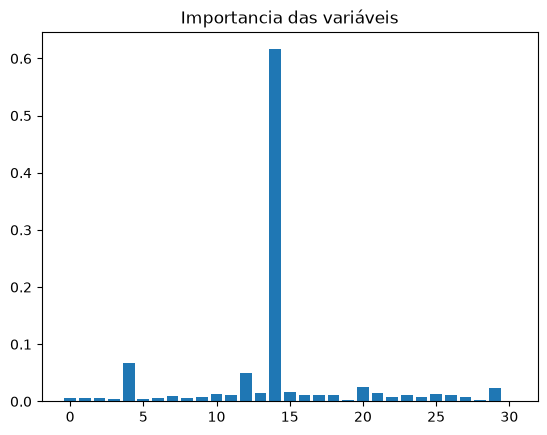

In [18]:
import matplotlib.pyplot as plt
importancias = xgb.feature_importances_

plt.bar(range(len(importancias)), importancias)
plt.title("Importancia das variáveis")
plt.show()

Esse gráfico mostra quanto as variaveis vão influenciar na decisão do modelo;
O modelo não vai usar todas as variaveis para decisão, aqui podemos ver que a barra pouco antes de 15 vai carregar um padrão muito forte de fraude

## Ajuste de hiperparâmetros

Testamos várias combinações para melhorar o modelo

O grafico SHAP agregado mostra quais variaveis mais pesaram, em media, no grupo amostrado. A proxima celula seleciona uma fraude real do teste que o XGBoost marcou como fraude e mostra a contribuicao de cada variavel para aquela previsao. SHAP descreve o comportamento do modelo, nao causa fraude.

## Explicabilidade (SHAP)

SHAP mostra como cada variável influencia a decisão do modelo.

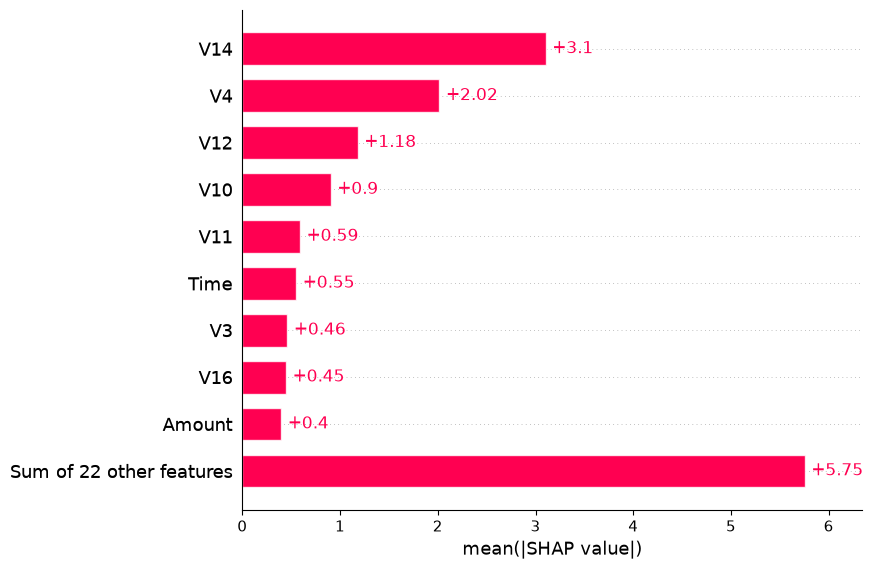

In [19]:
import shap

# Uma amostra reduz o custo de cálculo e a visualização local ajuda a interpretar o modelo.
explainer = shap.Explainer(xgb)
shap_values = explainer(x_test.iloc[:100])
shap.plots.bar(shap_values)

O gráfico de barras SHAP agrega a magnitude média das contribuições por variável; ele indica quais variáveis mais influenciam as previsões no conjunto amostrado. Para explicar uma transação específica, use `shap.plots.waterfall(shap_values[i])`. 

## Conclusao sobre os modelos

No teste final, a regressao logistica baseline obteve precisao **0,86**, recall **0,63** e F1 **0,73** para fraude. O Random Forest alcancou precisao **0,78**, recall **0,79** e F1 **0,79**. O XGBoost teve precisao **0,89**, recall **0,78** e F1 **0,83**. Assim, o XGBoost apresentou o melhor equilibrio geral pelo F1 e a maior precisao; o Random Forest encontrou ligeiramente mais fraudes. Como a diferenca de recall entre eles e pequena e o teste contem 148 fraudes, nao convem tratar essa ordem como definitiva.

O limiar **0,1147** foi escolhido para a regressao logistica na validacao, buscando recall minimo de 0,80. No teste, o recall foi **0,716** (precisao **0,746**, F1 **0,731**), mostrando que a meta da validacao nao se repetiu integralmente em dados separados. A escolha do limiar precisa equilibrar o custo de fraude perdida e o volume de alertas falsos.

A regressao logistica com treino balanceado por undersampling e SMOTE elevou o recall para **0,885** e **0,872**, mas a precisao caiu para **0,045** e **0,060**. Isso significa que esses modelos acionariam muitos alertas incorretos no limiar padrao de 0,50. Portanto, maximizar recall sozinho nao basta.
